<a href="https://colab.research.google.com/github/valentinabenitez-crypto/Cargar-COLLAB/blob/main/Parte_A_1_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# ENTREGA 1 - PARTE A
# Carga de datos desde GitHub

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Dirección del repositorio (corregida)
repo = "https://raw.githubusercontent.com/valentinabenitez-crypto/Cargar-COLLAB/main/Datos/"

# Cargar archivos
llenado = pd.read_csv(repo + "calidad_llenado.csv")
atributos = pd.read_csv(repo + "calidad_atributos.csv")
especificaciones = pd.read_csv(repo + "especificaciones_calidad.csv")
maestro = pd.read_csv(repo + "maestro_sku.csv")
demanda = pd.read_csv(repo + "demanda_semanal.csv")

# Verificar la carga
print("Archivos cargados correctamente")

print("Calidad llenado:", llenado.shape)
print("Calidad atributos:", atributos.shape)
print("Especificaciones:", especificaciones.shape)
print("Maestro SKU:", maestro.shape)
print("Demanda semanal:", demanda.shape)

display(llenado.head())

Archivos cargados correctamente
Calidad llenado: (4200, 10)
Calidad atributos: (210, 8)
Especificaciones: (3, 6)
Maestro SKU: (9, 13)
Demanda semanal: (1404, 10)


,subgrupo,fecha,semana_registro,turno,linea,sku,formato_L,hora,n_obs,volumen_mL
0,1,2026-07-20,1,A (06-14),L1,FUN-B05,0.5,06:00,1,500.86
1,1,2026-07-20,1,A (06-14),L1,FUN-B05,0.5,06:00,2,502.11
2,1,2026-07-20,1,A (06-14),L1,FUN-B05,0.5,06:00,3,503.12
3,1,2026-07-20,1,A (06-14),L1,FUN-B05,0.5,06:00,4,502.60
4,1,2026-07-20,1,A (06-14),L1,FUN-B05,0.5,06:00,5,499.11


Exploración y diagnóstico de los datos: comprobar que las mediciones de llenado estén correctamente registradas antes de construir las cartas de control.


In [ ]:
# BLOQUE 2: EXPLORACIÓN Y DIAGNÓSTICO DE DATOS

# Revisar las primeras 5 filas
print(llenado.head())

# Revisar cantidad de filas y columnas
print("Dimensiones:")
print(llenado.shape)

# Revisar nombres y tipos de columnas
print("Información general:")
llenado.info()

# Obtener estadísticas descriptivas
print("Estadísticas descriptivas:")
print(llenado.describe())

   subgrupo       fecha  semana_registro      turno linea      sku  formato_L  \
0         1  2026-07-20                1  A (06-14)    L1  FUN-B05        0.5   
1         1  2026-07-20                1  A (06-14)    L1  FUN-B05        0.5   
2         1  2026-07-20                1  A (06-14)    L1  FUN-B05        0.5   
3         1  2026-07-20                1  A (06-14)    L1  FUN-B05        0.5   
4         1  2026-07-20                1  A (06-14)    L1  FUN-B05        0.5   

    hora  n_obs  volumen_mL  
0  06:00      1      500.86  
1  06:00      2      502.11  
2  06:00      3      503.12  
3  06:00      4      502.60  
4  06:00      5      499.11  
Dimensiones:
(4200, 10)
Información general:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4200 entries, 0 to 4199
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   subgrupo         4200 non-null   int64  
 1   fecha            4200 non-null   objec

 Validación de datos
Antes de realizar el análisis estadístico del proceso de llenado, se realiza una validación inicial de la base de datos con el objetivo de identificar posibles problemas que puedan afectar los resultados. Para esto, se revisa la existencia de valores faltantes, registros duplicados, consistencia en el tamaño de los subgrupos de medición y distribución de las observaciones según línea de producción, formato y turno.
Esta etapa permite asegurar que los datos utilizados posteriormente para la construcción de cartas de control representen adecuadamente el comportamiento del proceso productivo.

In [ ]:
#BLOQUE 3 validación de datos
#1
# Revisar valores faltantes

print("Valores faltantes por columna:")
print(llenado.isnull().sum())

#2
#Revisar registros duplicados

print("Cantidad de filas duplicadas:")
print(llenado.duplicated().sum())

#3
# Revisar tamaño de los subgrupos

cantidad_subgrupo = llenado.groupby("subgrupo").size()

print("Cantidad de mediciones por subgrupo:")
print(cantidad_subgrupo.value_counts())

#4
# Identificar subgrupos que no tienen 5 observaciones

subgrupos_incorrectos = cantidad_subgrupo[cantidad_subgrupo != 5]

print("Subgrupos con cantidad distinta de 5:")
print(subgrupos_incorrectos)

# 5
#Revisar cantidad de mediciones por línea

print("Mediciones por línea:")
print(llenado["linea"].value_counts())


#6
# Revisar cantidad por formato

print("\nMediciones por formato:")
print(llenado["formato_L"].value_counts())


#7
# Revisar cantidad por turno

print("\nMediciones por turno:")
print(llenado["turno"].value_counts())

Valores faltantes por columna:
subgrupo           0
fecha              0
semana_registro    0
turno              0
linea              0
sku                0
formato_L          0
hora               0
n_obs              0
volumen_mL         0
dtype: int64
Cantidad de filas duplicadas:
0
Cantidad de mediciones por subgrupo:
5    840
Name: count, dtype: int64
Subgrupos con cantidad distinta de 5:
Series([], dtype: int64)
Mediciones por línea:
linea
L2    3000
L1    1200
Name: count, dtype: int64

Mediciones por formato:
formato_L
3.0    1560
1.5    1440
0.5    1200
Name: count, dtype: int64

Mediciones por turno:
turno
A (06-14)    1600
B (14-22)    1600
C (22-06)    1000
Name: count, dtype: int64


1. "La base de datos de llenado no presenta valores faltantes, por lo que todas las observaciones pueden ser consideradas en el análisis estadístico posterior."
2. "No se identificaron registros duplicados, evitando que algunas mediciones tengan una influencia artificialmente mayor dentro del análisis."
3. Todos los subgrupos contienen cinco observaciones, cumpliendo la estructura necesaria para aplicar cartas de control X̄–R.
4. No se encontraron subgrupos con tamaños incorrectos, por lo que no fue necesario realizar ajustes en la estructura de los datos.
5. La línea L2 concentra la mayor cantidad de mediciones (3000), mientras que L1 posee 1200 observaciones. El análisis posterior considerará cada línea por separado.
6. Se identificaron tres formatos de producción (0,5 L, 1,5 L y 3,0 L). Debido a sus diferentes volúmenes nominales, serán analizados de manera independiente.
7. Se cuenta con registros de los tres turnos de operación, permitiendo evaluar posteriormente si existen diferencias asociadas al turno de producción.

PREPARACIÓN DE DATOS CARTAS X-R
Para construir las cartas de control X̄–R, se agrupan las mediciones individuales en subgrupos racionales de cinco observaciones. Para cada subgrupo se calcula el promedio del volumen y el rango, permitiendo evaluar tanto el nivel central del proceso como su variabilidad.

In [ ]:
#BLOQUE 4 Preparación de datos para cartas X-R
# Crear tabla con promedio y rango por subgrupo

datos_control = llenado.groupby("subgrupo").agg(media_volumen=("volumen_mL", "mean"),
    rango_volumen=("volumen_mL", lambda x: x.max() - x.min()),
    linea=("linea", "first"),
    formato_L=("formato_L", "first"),
    turno=("turno", "first")
).reset_index()


# Mostrar primeros resultados

datos_control.head()


,subgrupo,media_volumen,rango_volumen,linea,formato_L,turno
0,1,501.560,4.01,L1,0.5,A (06-14)
1,2,501.752,5.17,L1,0.5,A (06-14)
2,3,503.630,4.13,L1,0.5,A (06-14)
3,4,503.172,2.10,L1,0.5,A (06-14)
4,5,503.396,8.49,L1,0.5,B (14-22)


Se transformaron las mediciones individuales en subgrupos racionales de cinco observaciones, calculando para cada uno la media y el rango del volumen de llenado. Esta estructura permitirá construir las cartas X̄–R, evaluando tanto el nivel promedio del proceso como su variabilidad.

 Separación de procesos por línea y formato
Y escribe:
Debido a que el proceso de llenado presenta diferentes líneas de producción y formatos de producto, los análisis estadísticos se realizarán de manera independiente para cada combinación línea-formato. Esto permite comparar procesos equivalentes y evitar distorsiones producto de diferencias en los volúmenes nominales.

In [ ]:
#BLOQUE 5 Separación de procesos para análisis estadístico
# Revisar combinaciones de línea y formato

datos_control[["linea", "formato_L"]].drop_duplicates()

# Separar procesos por línea y formato

proceso_L1_05 = datos_control[
    (datos_control["linea"] == "L1") &
    (datos_control["formato_L"] == 0.5)
]

proceso_L2_15 = datos_control[
    (datos_control["linea"] == "L2") &
    (datos_control["formato_L"] == 1.5)
]

proceso_L2_30 = datos_control[
    (datos_control["linea"] == "L2") &
    (datos_control["formato_L"] == 3.0)
]


print("L1 - 0.5 L:", proceso_L1_05.shape)
print("L2 - 1.5 L:", proceso_L2_15.shape)
print("L2 - 3.0 L:", proceso_L2_30.shape)

L1 - 0.5 L: (240, 6)
L2 - 1.5 L: (288, 6)
L2 - 3.0 L: (312, 6)


Se identificaron tres combinaciones de línea y formato, las cuales fueron separadas para realizar el análisis estadístico de manera independiente y evitar mezclar procesos con distintos volúmenes nominales.
¿Qué significa el resultado (240, 6)?
- 240: cantidad de subgrupos correspondientes a la línea L1 y formato 0,5 L.
- 6: cantidad de columnas de nuestra tabla datos_control.

In [ ]:
#BLOQUE 6 : COMPROBACIONES
# Agregar la semana de cada subgrupo a datos_control

semana_subgrupo = llenado[
    ["subgrupo", "semana_registro"]
].drop_duplicates()

datos_control = pd.merge(
    datos_control,
    semana_subgrupo,
    on="subgrupo",
    how="left"
)

display(datos_control.head())

,subgrupo,media_volumen,rango_volumen,linea,formato_L,turno,semana_registro
0,1,501.560,4.01,L1,0.5,A (06-14),1
1,2,501.752,5.17,L1,0.5,A (06-14),1
2,3,503.630,4.13,L1,0.5,A (06-14),1
3,4,503.172,2.10,L1,0.5,A (06-14),1
4,5,503.396,8.49,L1,0.5,B (14-22),1


In [ ]:
# Cantidad de subgrupos por semana y proceso

print(
    datos_control.groupby(
        ["linea", "formato_L", "semana_registro"]
    ).size()
)

linea  formato_L  semana_registro
L1     0.5        1                  24
                  2                  24
                  3                  24
                  4                  24
                  5                  24
                  6                  24
                  7                  24
                  8                  24
                  9                  24
                  10                 24
L2     1.5        1                  20
                  2                  32
                  3                  28
                  4                  40
                  5                  16
                  6                  24
                  7                  32
                  8                  24
                  9                  36
                  10                 36
       3.0        1                  40
                  2                  28
                  3                  32
                  4                  20
      

In [12]:
# BLOQUE 7: DEFINICIÓN DE FASE I Y FASE II

datos_control["fase"] = "II"

datos_control.loc[
    datos_control["semana_registro"].isin([1, 2]),
    "fase"
] = "I"

print(datos_control["fase"].value_counts())

display(datos_control.head())

fase
II    672
I     168
Name: count, dtype: int64


,subgrupo,media_volumen,rango_volumen,linea,formato_L,turno,semana_registro,fase
0,1,501.560,4.01,L1,0.5,A (06-14),1,I
1,2,501.752,5.17,L1,0.5,A (06-14),1,I
2,3,503.630,4.13,L1,0.5,A (06-14),1,I
3,4,503.172,2.10,L1,0.5,A (06-14),1,I
4,5,503.396,8.49,L1,0.5,B (14-22),1,I


In [14]:
# FASE I DEL PROCESO L1 - 0.5 L

fase1_L1_05 = datos_control[
    (datos_control["linea"] == "L1") &
    (datos_control["formato_L"] == 0.5) &
    (datos_control["fase"] == "I")
]

print("Cantidad de subgrupos en Fase I:")
print(fase1_L1_05.shape[0])

Cantidad de subgrupos en Fase I:
48


In [15]:
# Promedio de las medias de los subgrupos
media_medias = fase1_L1_05["media_volumen"].mean()

# Promedio de los rangos de los subgrupos
media_rangos = fase1_L1_05["rango_volumen"].mean()

print("Media de medias:", media_medias)
print("Media de rangos:", media_rangos)

Media de medias: 502.643625
Media de rangos: 4.749583333333333


Obtenemos desde las tablas impartidas en clases de calidad 2 las constantes # Constantes para cartas X barra - R con subgrupos de tamaño n = 5
A2 = 0.577
D3 = 0
D4 = 2.114

In [17]:
# Constantes para n = 5
A2 = 0.577
D3 = 0
D4 = 2.114

# Límites de la carta R
LC_R = media_rangos
LSC_R = D4 * media_rangos
LIC_R = D3 * media_rangos

# Límites de la carta X barra
LC_X = media_medias
LSC_X = media_medias + A2 * media_rangos
LIC_X = media_medias - A2 * media_rangos

print("Carta R")
print("LIC:", LIC_R)
print("LC:", LC_R)
print("LSC:", LSC_R)

print("\nCarta X barra")
print("LIC:", LIC_X)
print("LC:", LC_X)
print("LSC:", LSC_X)

Carta R
LIC: 0.0
LC: 4.749583333333333
LSC: 10.040619166666666

Carta X barra
LIC: 499.90311541666665
LC: 502.643625
LSC: 505.3841345833333


In [18]:
# Revisar puntos fuera de los límites en la carta R - Fase I

fuera_R = fase1_L1_05[
    (fase1_L1_05["rango_volumen"] > LSC_R) |
    (fase1_L1_05["rango_volumen"] < LIC_R)
]

print("Subgrupos fuera de control en la carta R:")
display(fuera_R)

Subgrupos fuera de control en la carta R:


,subgrupo,media_volumen,rango_volumen,linea,formato_L,turno,semana_registro,fase
91,92,502.946,10.06,L1,0.5,B (14-22),2,I


In [19]:
# Revisar las mediciones originales del subgrupo 92

subgrupo_92 = llenado[
    llenado["subgrupo"] == 92
]

display(subgrupo_92)

,subgrupo,fecha,semana_registro,turno,linea,sku,formato_L,hora,n_obs,volumen_mL
455,92,2026-07-27,2,B (14-22),L1,CIT-L05,0.5,20:00,1,503.56
456,92,2026-07-27,2,B (14-22),L1,CIT-L05,0.5,20:00,2,503.12
457,92,2026-07-27,2,B (14-22),L1,CIT-L05,0.5,20:00,3,506.54
458,92,2026-07-27,2,B (14-22),L1,CIT-L05,0.5,20:00,4,505.03
459,92,2026-07-27,2,B (14-22),L1,CIT-L05,0.5,20:00,5,496.48


Ahora tenemos que seguir investigando porque hay ese valor en este subgrupo por lo que iniciaremos una búsqueda de que salio mal, primero veremos los subgrupos cercanos para tener mas info

In [20]:
# Revisar subgrupos cercanos al 92

vecinos_92 = datos_control[
    (datos_control["linea"] == "L1") &
    (datos_control["formato_L"] == 0.5) &
    (datos_control["subgrupo"] >= 88) &
    (datos_control["subgrupo"] <= 96)
]

display(
    vecinos_92[
        ["subgrupo", "media_volumen", "rango_volumen",
         "turno", "semana_registro"]
    ]
)

,subgrupo,media_volumen,rango_volumen,turno,semana_registro
87,88,503.312,1.87,A (06-14),2
88,89,502.768,6.72,B (14-22),2
89,90,502.888,6.26,B (14-22),2
90,91,503.330,5.80,B (14-22),2
91,92,502.946,10.06,B (14-22),2
92,93,501.440,5.88,A (06-14),2
93,94,503.434,5.98,A (06-14),2
94,95,501.722,4.17,A (06-14),2
95,96,502.652,4.58,A (06-14),2


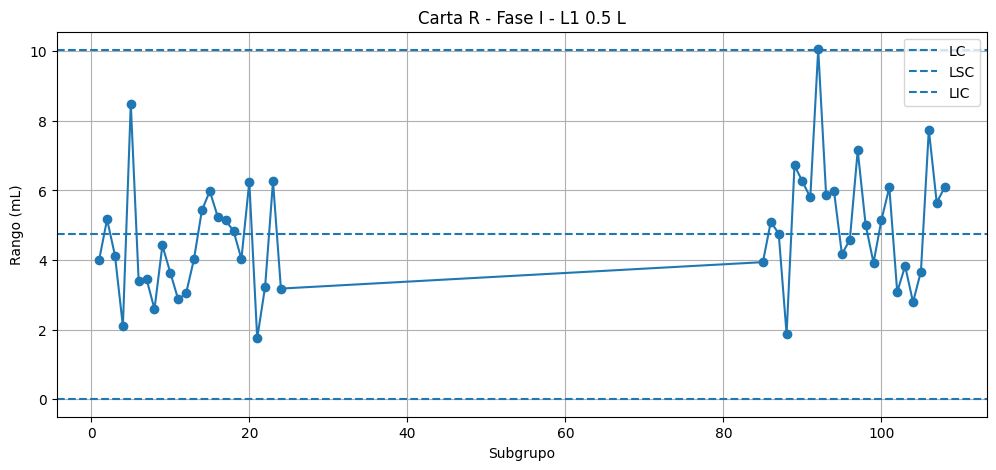

In [21]:
# Carta R - Fase I - L1 0.5 L

plt.figure(figsize=(12, 5))

plt.plot(
    fase1_L1_05["subgrupo"],
    fase1_L1_05["rango_volumen"],
    marker="o"
)

plt.axhline(LC_R, linestyle="--", label="LC")
plt.axhline(LSC_R, linestyle="--", label="LSC")
plt.axhline(LIC_R, linestyle="--", label="LIC")

plt.xlabel("Subgrupo")
plt.ylabel("Rango (mL)")
plt.title("Carta R - Fase I - L1 0.5 L")

plt.legend()
plt.grid()

plt.show()

In [22]:
# Crear orden consecutivo para los subgrupos de Fase I
fase1_L1_05 = fase1_L1_05.copy()

fase1_L1_05["orden"] = range(1, len(fase1_L1_05) + 1)

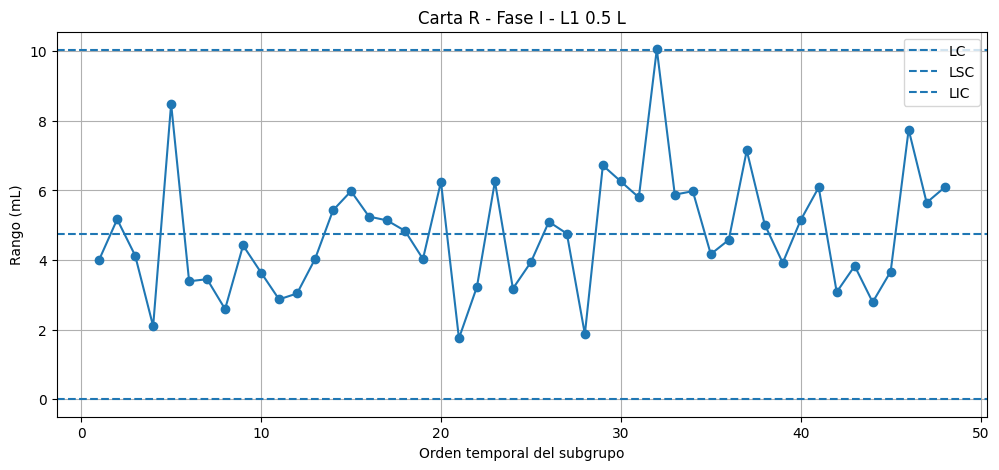

In [23]:
# Carta R - Fase I - L1 0.5 L

plt.figure(figsize=(12, 5))

plt.plot(
    fase1_L1_05["orden"],
    fase1_L1_05["rango_volumen"],
    marker="o"
)

plt.axhline(LC_R, linestyle="--", label="LC")
plt.axhline(LSC_R, linestyle="--", label="LSC")
plt.axhline(LIC_R, linestyle="--", label="LIC")

plt.xlabel("Orden temporal del subgrupo")
plt.ylabel("Rango (mL)")
plt.title("Carta R - Fase I - L1 0.5 L")

plt.legend()
plt.grid()

plt.show()

In [24]:
# Regla 1: punto fuera de los límites de control

regla1_R = fase1_L1_05[
    (fase1_L1_05["rango_volumen"] > LSC_R) |
    (fase1_L1_05["rango_volumen"] < LIC_R)
]

print("Regla 1 - Puntos fuera de los límites:")
display(regla1_R)

Regla 1 - Puntos fuera de los límites:


,subgrupo,media_volumen,rango_volumen,linea,formato_L,turno,semana_registro,fase,orden
91,92,502.946,10.06,L1,0.5,B (14-22),2,I,32


Se optó por aplicar un conjunto acotado de reglas de Nelson, evitando mezclar criterios de distintos sistemas y reduciendo el riesgo de falsas alarmas. Se consideraron tres patrones principales: puntos fuera de los límites de control, rachas prolongadas al mismo lado de la línea central y tendencias sostenidas crecientes o decrecientes. Esta selección permite detectar tanto señales extremas como comportamientos no aleatorios del proceso, manteniendo el análisis consistente con lo revisado en clases. 2_Calidad_II

In [25]:
# Regla 2 de Nelson:
# 9 puntos consecutivos al mismo lado de la línea central

valores_R = fase1_L1_05["rango_volumen"].tolist()
subgrupos_R = fase1_L1_05["subgrupo"].tolist()

senales_regla2 = []

for i in range(len(valores_R) - 8):

    grupo = valores_R[i:i+9]

    todos_arriba = all(valor > LC_R for valor in grupo)
    todos_abajo = all(valor < LC_R for valor in grupo)

    if todos_arriba or todos_abajo:
        senales_regla2.append(subgrupos_R[i:i+9])

print("Regla 2 - 9 puntos consecutivos al mismo lado de LC:")
print(senales_regla2)

Regla 2 - 9 puntos consecutivos al mismo lado de LC:
[]
